## Statistical mechanics of dense ionized matter. VII. Equation of state and phase separation of ionic mixtures in a uniform background

**Цель:** воспроизвести парные корреляционные функции и внутреннюю энергию бинарной ионной смеси с $Z_1=1$, $Z_2=2$ в однородном нейтрализующем фоне и проверить согласие с результатами статьи 1977 года.

**Оригинальная статья:** J. P. Hansen, G. M. Torrie, P. Vieillefosse, *Physical Review A* **16**, 2153 (1977). [Статья на сайте издателя](https://journals.aps.org/pra/abstract/10.1103/PhysRevA.16.2153), DOI: [10.1103/PhysRevA.16.2153](https://doi.org/10.1103/PhysRevA.16.2153).

В ноутбуке сравниваются корреляционные функции $g_{11}$, $g_{12}$, $g_{22}$, полученные методами HNC и Монте-Карло, а также значения безразмерной внутренней энергии $u$ в приближениях HNC, нелинейного и линейного Дебая–Хюккеля. Для численной проверки таблицы I используются $\Gamma=0.1$ и $1.0$, $x_1=1,\;0.75,\;0.5,\;0.25,\;0$.


![](photos/image.png)
![](photos/image_copy.png)

### Дискретное синус-преобразование (`scipy.fft.dst`)

$$
Y_k = 2\sum_{n=0}^{N-1}x_n
\sin\left(\frac{\pi(k+1)(n+1)}{N+1}\right)
$$

###  Метод Симпсона (`scipy.integrate.simpson`)

$$
\int_a^b f(x)\,dx
\approx \frac{b-a}{6}
\left[f(a)+4f\left(\frac{a+b}{2}\right)+f(b)\right]
$$

###  Решение краевой задачи (`scipy.integrate.solve_bvp`)

$$
\frac{d\mathbf y}{dx}= \mathbf f(x,\mathbf y,\mathbf p)
$$

$$
\mathbf{bc}(\mathbf y(a),\mathbf y(b),\mathbf p)=0
$$


# Start

In [9]:
import math
from itertools import product
import numpy as np
from scipy.fft import dst
from scipy.integrate import simpson, solve_bvp
from scipy.optimize import root
from scipy.special import erfc
from numba import njit

Ограничение вычислений с помощью заданной максимальной длины `mmax`

$$
\sqrt{m_x^2 + m_y^2 + m_z^2} \leq m_{\max}
$$

$$
\mathbf{k} = \frac{2\pi}{L}(m_x, m_y, m_z)
$$

$$
w_{\mathbf{k}} = \frac{4\pi}{L^3} \frac{\exp\left(-\frac{k^2}{4\alpha^2}\right)}{k^2}
$$

In [20]:
# Создание коэфициентов для метода Эвальда
def wave_vectors(L, alpha=0.8, mmax=8):
    m = np.array(list(product(range(-mmax, mmax + 1), repeat=3)))
    m2 = np.sum(m*m, axis=1)
    m = m[(m2 > 0) & (m2 <= mmax*mmax)]
    k = 2*np.pi*m/L
    k2 = np.sum(k*k, axis=1)
    weight = 2*np.pi/L**3 * np.exp(-k2/(4*alpha*alpha))/k2
    return k, weight

$$
E_{ij}^{\mathrm{real}} = z_i z_j \frac{\operatorname{erfc}(\alpha r)}{r}
$$

$$
E_i^{\mathrm{real}}(\mathbf{r}) =
z_i \sum_{j \neq i} z_j \sum_{\mathbf{n}}
\frac{\operatorname{erfc}(\alpha r_{ij,\mathbf{n}})}{r_{ij,\mathbf{n}}}
$$

In [24]:
@njit
# Вычисление ближней части электрической энергии
def local_real(poss, charges, L, alpha, rc, i, new):
    E = 0.0
    for j in range(len(charges)):
        if i == j:
            continue
        d = new - poss[j]
        for nx in range(-1, 2):
            for ny in range(-1, 2):
                for nz in range(-1, 2):
                    dx, dy, dz = d + L * np.array([nx, ny, nz])
                    r2 = dx**2 + dy**2 + dz**2
                    if 0 < r2 < rc**2:
                        r = math.sqrt(r2)
                        E += charges[j] * math.erfc(alpha*r) / r
    return charges[i] * E

$$
C_{\mathbf{k}} = \sum_{i=1}^{N} z_i \cos(\mathbf{k} \cdot \mathbf{r}_i)
$$

$$
S_{\mathbf{k}} = \sum_{i=1}^{N} z_i \sin(\mathbf{k} \cdot \mathbf{r}_i)
$$

$$
\mathbf{r}_i' = (\mathbf{r}_i + \boldsymbol{\delta}) \bmod L
$$

$$
\Delta E_{\mathrm{real}} =
E_{\mathrm{real}}(\mathbf{r}_i') -
E_{\mathrm{real}}(\mathbf{r}_i)
$$

### Дальняя энергия Эвальда

$$
E_{\mathrm{rec}} =
\sum_{\mathbf{k}} w_{\mathbf{k}}
\left(C_{\mathbf{k}}^2 + S_{\mathbf{k}}^2\right)
$$

$$
\Delta E_{\mathrm{rec}} =
\sum_{\mathbf{k}} w_{\mathbf{k}}
\left[
2C_{\mathbf{k}}\Delta C_{\mathbf{k}}
+(\Delta C_{\mathbf{k}})^2
+2S_{\mathbf{k}}\Delta S_{\mathbf{k}}
+(\Delta S_{\mathbf{k}})^2
\right]
$$

$$
w_{\mathbf{k}} =
\frac{2\pi}{L^3}
\frac{\exp\left(-\frac{k^2}{4\alpha^2}\right)}{k^2}
$$

### Вероятность принятия Metropolis

$$
\Delta E = \Delta E_{\mathrm{real}}+\Delta E_{\mathrm{rec}}
$$

$$
P_{\mathrm{accept}} = \min\left(1,e^{-\Gamma\Delta E}\right)
$$

### Обновление состояний при принятии

$$
\begin{aligned}
\mathbf{r}_i &\leftarrow \mathbf{r}_i' \\[6pt]
C_{\mathbf{k}} &\leftarrow C_{\mathbf{k}}+\Delta C_{\mathbf{k}} \\[6pt]
S_{\mathbf{k}} &\leftarrow S_{\mathbf{k}}+\Delta S_{\mathbf{k}}
\end{aligned}
$$

In [ ]:
# Реализация алгоритма Metropolis Monte Carlo.
@njit
def mc_kernel(poss, charges, L, G, alpha, rc, k, w, warmup, production, every, step):

    N = len(charges)

    # Fourier-компоненты начальной конфигурации
    phase = poss @ k.T
    co, si = np.cos(phase), np.sin(phase)
    C = np.sum(charges[:, None] * co, axis=0)
    S = np.sum(charges[:, None] * si, axis=0)

    samples = np.empty((production // every, N, 3))
    saved = accepted = 0

    for sweep in range(warmup + production):
        for _ in range(N):
            # Случайно двигаем один ион
            i = np.random.randint(N)
            new = (poss[i] + np.random.uniform(-step, step, 3)) % L
            # Изменение ближней энергии
            de = (local_real(poss, charges, L, alpha, rc, i, new) - local_real(poss, charges, L, alpha, rc, i, poss[i]))
            # Изменение дальней энергии
            angle = k @ new
            c_new, s_new = np.cos(angle), np.sin(angle)

            dc = charges[i] * (c_new - co[i])
            ds = charges[i] * (s_new - si[i])

            de += np.sum(w * (2*C*dc + dc**2 + 2*S*ds + ds**2))

            # Metropolis
            if de <= 0 or np.random.random() < math.exp(-G*de):
                C += dc
                S += ds
                co[i], si[i], poss[i] = c_new, s_new, new

                if sweep >= warmup:
                    accepted += 1

        # Сохраняем конфигурации после прогрева
        if sweep >= warmup and (sweep - warmup + 1) % every == 0:
            samples[saved] = poss
            saved += 1

    return samples, accepted / (production*N)

In [ ]:
# Запуск Монте-Карло
def mc_gr(poss, charges, L, G=40, warmup=1500, production=6000, every=10, step=0.25):

    k, w = wave_vectors(L)
    samples, acc = mc_kernel(poss.copy(), charges.astype(float), L, G, 0.8, 6.0, k, w, warmup, production, every, step)
    edges = np.linspace(0, 4, 81)
    i, j = np.triu_indices(len(charges), 1)
    # Типы пар: 0 = (1,1), 1 = (1,2), 2 = (2,2)
    kind = np.where(charges[i] == charges[j], 2*(charges[i]-1), 1)
    counts = np.zeros((3, 80))

    for frame in samples:
        d = frame[i] - frame[j]
        d -= L * np.rint(d/L)
        r = np.linalg.norm(d, axis=1)
        counts += np.histogram2d(kind, r, bins=([-0.5, 0.5, 1.5, 2.5], edges))[0]

    N1 = (charges == 1).sum()
    N2 = len(charges) - N1

    shell = 4*np.pi/3 * np.diff(edges**3)
    norm = np.array([N1**2/2, N1*N2, N2**2/2])[:, None]
    g = counts * L**3 / (len(samples) * norm * shell)

    return (edges[:-1] + edges[1:])/2, g, acc

### Кулоновское взаимодействие

$$
\beta V_{\alpha\beta}(r) = \frac{\Gamma Z_\alpha Z_\beta}{r}
$$

$$
v_{\alpha\beta}^{s}(r) = Z_\alpha Z_\beta \frac{\operatorname{erfc}(r)}{r}
$$

### Дальняя часть в Fourier-пространстве

$$
\widetilde{v}_{\alpha\beta}^{l}(q) =
\frac{3Z_\alpha Z_\beta}{q^2}e^{-q^2/4}
$$

### HNC Closure

$$
h_{\alpha\beta}(r) = g_{\alpha\beta}(r) - 1
$$

$$
y_{\alpha\beta}(r) = h_{\alpha\beta}(r) - c_{\alpha\beta}^{s}(r)
$$

$$
g_{\alpha\beta}(r) =
\exp\left[y_{\alpha\beta}(r) - \Gamma v_{\alpha\beta}^{s}(r)\right]
$$

$$
c_{\alpha\beta}^{s}(r) =
g_{\alpha\beta}(r) - 1 - y_{\alpha\beta}(r)
$$

### Обратное Fourier-преобразование

$$
f(r) = \frac{2}{3\pi r}
\int_0^\infty q\widetilde{f}(q)\sin(qr)\,dq
$$

### Полная прямая корреляционная функция в Fourier-пространстве

$$
\widetilde{c}_{\alpha\beta}(q) =
\widetilde{c}_{\alpha\beta}^{s}(q) -
\frac{3\Gamma Z_\alpha Z_\beta}{q^2}e^{-q^2/4}
$$

### Ornstein–Zernike

$$
\widetilde{h}_{\alpha\beta}(q) =
\widetilde{c}_{\alpha\beta}(q) +
\sum_{\gamma=1}^{2}
x_\gamma
\widetilde{c}_{\alpha\gamma}(q)
\widetilde{h}_{\gamma\beta}(q)
$$

### Вычисление внутренней энергии (`simpson()`)

$$
u = \frac{3\Gamma}{2}
\sum_{\alpha,\beta=1}^{2}
x_\alpha x_\beta Z_\alpha Z_\beta
\int_0^\infty [g_{\alpha\beta}(r)-1]r\,dr
$$

In [ ]:
# Вычисление напрямую без перемещения ионов
def hnc(G, x1=0.5):
    dr, n = 0.025, 1024
    r = dr * np.arange(1, n)
    q = np.pi * np.arange(1, n) / (n*dr)

    z = np.array([1., 2., 4.])[:, None]
    x2 = 1-x1
    v = z*erfc(r)/r
    tail = 3*z*np.exp(-q*q/4)/q**2
    F, I = 3*dr/(2*q), q[0]/(3*np.pi*r)
    y = np.zeros((3, n-1))

    for gamma in [t for t in [.05,.1,.3,1,2,4,8,12,20,30,40] if t < G] + [G]:

        def residual(flat):
            yy = flat.reshape(3, -1)
            cs = F*dst(r*(np.expm1(np.clip(yy-gamma*v, -745, 50))-yy), type=1, axis=-1)

            a, b, d = cs-gamma*tail
            cross = a*d-b*b
            h = np.array([a-x2*cross, b, d-x1*cross]) / (1-x1*a-x2*d+x1*x2*cross)
            return (I*dst(q*(h-cs), type=1, axis=-1)-yy).ravel()

        sol = root(residual, y.ravel(), method='anderson', options={'maxiter':600, 'fatol':2e-7,'jac_options':{'M':12, 'alpha':.03}})

        y = sol.x.reshape(3, -1)

    g = np.exp(y-G*v)
    area = simpson(np.c_[np.zeros(3), (g-1)*r], x=np.r_[0,r], axis=1)
    u = 1.5*G*np.sum(np.array([x1*x1, 2*x1*x2, x2*x2])*z[:,0]*area)

    return r, g, u

### Параметр экранирования

$$
\kappa = \sqrt{3\Gamma \sum_j x_j Z_j^2}
$$

### Функция распределения после нахождения потенциала

$$
g_{ij}(r) = e^{-Z_j\psi_i(r)}
$$

### Вычисление внутренней энергии

$$
u = \frac{3\Gamma}{2}
\sum_{i,j=1}^{2}
x_i x_j Z_i Z_j
\int_0^\infty [g_{ij}(r)-1]r\,dr
$$

In [ ]:
# вычисляем средний электрический потенциал вокруг иона и через него получаем распределения
def nonlinear_dh(G, x1):
    z = np.array([1., 2.])
    x = np.array([x1, 1-x1])

    kappa = np.sqrt(3*G*np.sum(x*z**2))
    R = max(40., 35/kappa)
    t = np.linspace(0, R, 1200)
    def ode(r, y):
        psi = np.divide(y[0], r, out=np.full_like(r, 1e6), where=r>0)
        rhs = -3*G*r*np.sum((x*z)[:, None]*np.expm1(-z[:, None]*psi), axis=0)
        return np.vstack((y[1], rhs))
    u = 0.
    for zi, xi in zip(z, x):
        def bc(a, b):
            return np.array([a[0]-G*zi, b[0]])

        e = np.exp(-kappa*t)
        guess = np.vstack((G*zi*e, -kappa*G*zi*e))
        sol = solve_bvp(ode, bc, t, guess, tol=3e-7, max_nodes=20000)

        r = np.linspace(0, R, 18001)
        psi = np.divide(sol.sol(r)[0], r, out=np.full_like(r, np.inf), where=r>0)
        h = np.expm1(-z[:, None]*psi)
        u += xi*zi*np.sum(x*z*simpson(h*r, x=r, axis=1))

    return 1.5*G*u

$$
\langle Z^2 \rangle = x_1 Z_1^2 + x_2 Z_2^2
$$

$$
u_{\mathrm{DH}} = -\frac{\sqrt{3}}{2}
\left(\Gamma \langle Z^2 \rangle\right)^{3/2}
$$

In [ ]:
# линейная теория Дебая–Хюккеля
def linear_dh(G, x1):
    mean_z2 = x1*1**2 + (1-x1)*2**2
    return -np.sqrt(3)/2 * (G*mean_z2)**1.5

Доля принятых движений: 30.3%


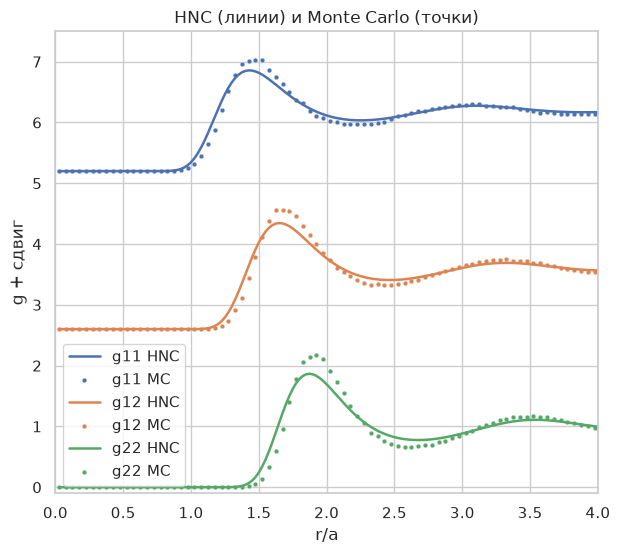

In [ ]:
import seaborn as sns

sns.set_theme(style="whitegrid")

r, g, accept = mc_gr(poss, charges, L, G)
r_hnc, g_hnc, _ = hnc(G, x1)
colors = sns.color_palette("deep", 3)
ax = None
for a, label, shift in [(0, '11', 5.2), (1, '12', 2.6), (2, '22', 0)]:
    ax = sns.lineplot(x=r_hnc, y=g_hnc[a] + shift, color=colors[a], lw=1.8, ax=ax, label=f'g{label} HNC')
    sns.scatterplot(x=r, y=g[a] + shift,color=colors[a], s=12, ax=ax, label=f'g{label} MC')

ax.figure.set_size_inches(7, 6)
ax.set(xlim=(0, 4), ylim=(-0.1, 7.5), xlabel='r/a', ylabel='g + сдвиг', title='HNC (линии) и Monte Carlo (точки)')
ax.legend()

print(f'Доля принятых движений: {accept:.1%}')

![](photos/stat2.png)

In [29]:
import pandas as pd

rows = []
for gamma in [0.1, 1.0]:
    for x in [1.0, 0.75, 0.5, 0.25, 0.0]:
        rows.append([gamma, x, hnc(gamma, x)[2], nonlinear_dh(gamma, x), linear_dh(gamma, x)])
table = pd.DataFrame(rows, columns=['Г', 'x1', 'HNC', 'Nonlinear DH', 'Linear DH'])
display(table.round(6))

,Г,x1,HNC,Nonlinear DH,Linear DH
0,0.1,1.00,-0.025689,-0.025591,-0.027386
1,0.1,0.75,-0.055739,-0.055207,-0.063400
2,0.1,0.50,-0.091421,-0.090198,-0.108253
3,0.1,0.25,-0.131682,-0.129552,-0.160456
4,0.1,0.00,-0.175873,-0.172641,-0.219089
5,1.0,1.00,-0.570455,-0.548462,-0.866025
6,1.0,0.75,-1.074887,-1.012960,-2.004877
7,1.0,0.50,-1.638991,-1.528725,-3.423266
8,1.0,0.25,-2.253171,-2.087897,-5.074061
9,1.0,0.00,-2.910912,-2.684926,-6.928203


![](photos/stat1.png)

## Вывод и погрешность воспроизведения

**Результат статьи 1977 года подтверждён для проверенных значений внутренней энергии:** сохранённая расчётная таблица воспроизводит таблицу I оригинальной статьи с максимальной относительной погрешностью **0.0623%** по всем 30 сравниваемым значениям (10 наборов параметров, 3 приближения).

Погрешность рассчитана относительно опубликованных значений:

$$
\Delta u = |u_{\mathrm{расчёт}}-u_{\mathrm{статья}}|,\qquad
\delta = \frac{|u_{\mathrm{расчёт}}-u_{\mathrm{статья}}|}{|u_{\mathrm{статья}}|}\,100\%.
$$

| Приближение | Максимальная абсолютная погрешность $\Delta u$ | Максимальная относительная погрешность $\delta$ |
|:---|---:|---:|
| HNC | $1.71\times10^{-4}$ | 0.0623% |
| Нелинейное Дебая–Хюккеля | $7\times10^{-6}$ | 0.000365% |
| Линейное Дебая–Хюккеля | $4\times10^{-6}$ | 0.001577% |

Наибольшее относительное расхождение получено для HNC при $\Gamma=0.1$, $x_1=0.25$: $u_{\mathrm{расчёт}}=-0.131682$, $u_{\mathrm{статья}}=-0.1316$, откуда $\Delta u=0.000082$ и $\delta\approx0.06231\%$. Средняя относительная погрешность HNC по 10 строкам составляет **0.0167%**. Максимумы абсолютной и относительной погрешностей в таблице могут приходиться на разные строки.
